In [1]:
import numpy as np
from pathlib import Path
import pandas as pd
import sys
sys.path.insert(1, '../../')
from util.overshoots import OS_model
from util.plot import lighten_color

import scipy as sp
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrow,FancyArrowPatch
from matplotlib.gridspec import GridSpec

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

from mpl_toolkits.basemap import Basemap
import networkx as nx
import illustrative_fig

def OS_fit(xdata,ydata,p0=None):
    if type(p0)==type(None):
        p0=[ydata[0], ydata.max(), ydata[-1], 
            xdata[np.argmax(ydata)], 10 , (xdata[-1]-xdata[np.argmax(ydata)])/2]
    return curve_fit(OS_model, xdata, ydata,
                       p0=p0,
                       bounds = ([ydata[0]-0.5, ydata.max()-0.5, ydata[-1]-0.5, 
                                  0, 0, 0],
                                 [ydata[0]+0.5, ydata.max()+0.5, ydata[-1]+0.5, 
                                  len(xdata), 100, len(xdata)]) )

def make_legend_arrow(legend, orig_handle,
                      xdescent, ydescent,
                      width, height, fontsize):
    p = mpl.patches.FancyArrow(0, 0.5*height, width, 0, length_includes_head=True, head_width=0.75*height )
    return p

font = {'size':10}
mpl.rc('font', **font)

df_interactions = pd.read_excel('../../../Data/Interactions_TableA2.xlsx',usecols='A:F',header=[0],sheet_name='Interactions')

# Developing individual subpanels

## designing the network subpanel
The cells hidden below show the testing and developing.
The final function to plot this network panel is illustrative_fig.network_panel()

In [ ]:
G = nx.from_pandas_edgelist(df_interactions,source='Source',target='Target',edge_attr=['min', 'max'],create_using=nx.DiGraph)
earc_dic = {e:0 for e in G.edges}
earc_dic[('GIS','AMOC')]=0.2
earc_dic[('AMOC','GIS')]=0.2
earc_dic[('AMOC','WAIS')]=-0.5
earc_dic[('AMOC','ENSO')]=0.3
earc_dic[('WAIS','AMOC')]=0.3
earc_dic[('ASI','AMOC')]=0.15
earc_dic[('AMOC','ASI')]=0.15
earc_dic[('ASI','GIS')]=0.1
earc_dic[('PERM','AMOC')]=-0.15
earc_dic[('ASI','PERM')]=-0.1
earc_dic[('PERM','ASI')]=-0.1
earc_dic[('WAIS','GIS')]=-0.9
earc_dic[('GIS','WAIS')]=1.4

m = Basemap(projection='kav7',lon_0=-30,resolution='c',)
            # llcrnrlat=-80,urcrnrlat=80,llcrnrlon=-180,urcrnrlon=180,lat_ts=20,);
pos_lonlat = {'GIS':[-43,75], 'AMOC':[-30,40],'ENSO':[-115,-8.8],
              'WAIS':[-90,-75],'ASI':[0,68],'PERM':[70,60],
              'WAM':[0,15],'REEF':[-80,12],'AMAZ':[-62.2,-3.5]}
pos_xy ={k:m(v[0],v[1]) for k,v in pos_lonlat.items()}
xmax,ymax = (34667130.92439352,20015077.371242613)
T_lim_dic = df_TEs['Threshold (°C) – Est.'].to_dict()

node_labels = {'GIS':'Greenland ice sheet (GIS)', 'AMOC':'AMOC','ENSO':'ENSO',
              'WAIS':'West Antarctic ice sheet (WAIS)','ASI':'Arctic sea ice (ASI)','PERM':'Permafrost collapse (PERM)',
              'WAM':'West African monsoon (WAM)','REEF':'Coral reefs (REEF)','AMAZ':'Amazon dieback (AMAZ)'}
node_label_offsets = {'GIS': np.array([0,0.035]), 
                      'AMOC':np.array([-0.025,0.01]),
                      'ENSO':np.array([-.025,0]),
                      'WAIS':np.array([0,-0.035]),
                      'ASI':np.array([0.025,0.025]),#np.array([0,0.05]),
                      'PERM':np.array([0.025,0]),
                      'WAM':np.array([0,0.05]),
                      'REEF':np.array([0,0.05]),
                      'AMAZ':np.array([0,-0.042])}
node_label_pos = {k:np.array(v)+
                  node_label_offsets[k]*np.array([xmax,ymax])
                  for k,v in pos_xy.items()}
node_label_ha = {k:'center' for k in G.nodes}
node_label_ha['AMOC'] = 'right'
node_label_ha['ENSO'] = 'right'
node_label_ha['WAM'] = 'left'
node_label_ha['GIS'] = 'center'
node_label_ha['ASI'] = 'left'
node_label_ha['PERM'] = 'left'

node_label_va = {k:'bottom' if v[1]>0 else 'top' if v[1]<0 else 'center' 
                 for k,v in node_label_offsets.items()}

In [ ]:
fig,ax=plt.subplots(figsize=(10,8))

m.fillcontinents(color='tan',lake_color='tan',ax=ax,zorder=1);
m.drawcoastlines(color='k',zorder=0,ax=ax)

node_cmap = 'rocket'
vmin = -1
vmax = 7 
node_size=[1600/np.log(df_TEs.loc[n]['Collapse (years)']) for n in G.nodes]
nx.draw_networkx(G,ax=ax,pos=pos_xy,
                 node_size=node_size,with_labels=False,edgelist=[],
                 node_color=[T_lim_dic[n] for n in G.nodes()],
                 vmin=vmin,vmax=vmax,cmap=node_cmap)
for e in G.edges:
    vals = G.get_edge_data(e[0],e[1])
    if vals['min'] > 0: # Destabilising
        c = 'indianred'
        w = vals['max']
    elif vals['max'] < 0: # Stabilising
        c = 'royalblue'
        w= np.abs(vals['min'])
    else: # Unclear
        c = 'gray' 
        w = vals['max']
    nx.draw_networkx_edges(G,pos_xy,ax=ax,edgelist=[e], 
                           edge_color=c, width=np.log(w)*1.8,
                           node_size=[n+200 for n in node_size],
                           connectionstyle="arc3,rad=rrr".replace('rrr',str(earc_dic[e])),
                           arrowsize=20
                          );
for n,(x,y) in pos_xy.items():
    ax.annotate(node_labels[n], (x,y), node_label_pos[n],
                ha=node_label_ha[n],
                va=node_label_va[n],
                bbox=dict(facecolor='white', 
                          edgecolor='k', 
                          boxstyle='round,pad=0.2'))
# ax_leg = fig.add_axes((0.65,0.23,0.25,0.2))
# ax_leg.set_xticks([])
# ax_leg.set_yticks([])

# size_disp = [10,100,1000,10000]
# ax_leg.scatter(np.log10(size_disp),[0]*len(size_disp),s=[1600/np.log(s) for s in size_disp])
# ax_leg.set_xlim(0,1+len(size_disp))

## adding critical thresholds to network panel

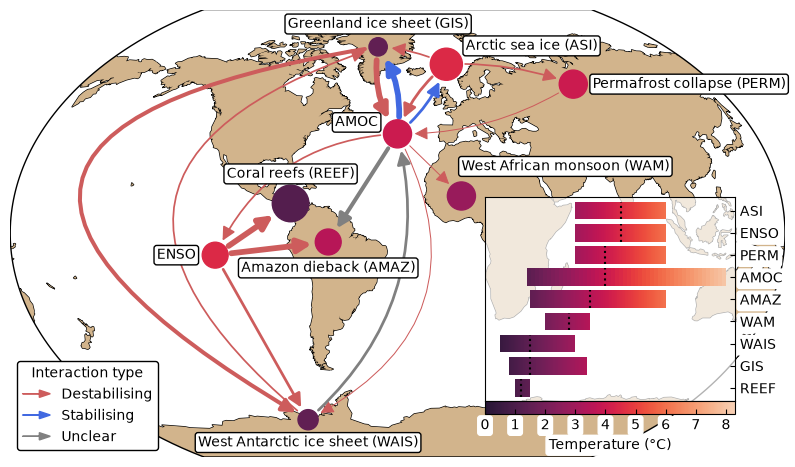

In [20]:
fig,ax=plt.subplots(figsize=(10,8))
illustrative_fig.network_panel(fig,ax)

ax_in = fig.add_axes((0.6,0.24,0.25,0.3))
ax_in.set_xlim([0,8.3])
ax_in.set_ylim([-.6,8.6])
illustrative_fig.threshold_inset(fig,ax_in)

### Development of including the critical thresholds as an inset on the network panel. 

The relevant function is now illustrative_fig.threshold_inset(fig,ax,*args)

In [ ]:
fig,ax=plt.subplots(figsize=(10,8))

m.fillcontinents(color='tan',lake_color='tan',ax=ax,zorder=1);
m.drawcoastlines(color='k',zorder=0)

bbox_node=dict(facecolor='white', 
               edgecolor='k', 
               boxstyle='round,pad=0.2')
bbox_white=dict(facecolor='white', 
               edgecolor='white', 
               boxstyle='round,pad=0.2')

node_cmap = 'rocket'
vmin = -1
vmax = 9 
node_size=[1600/np.log(df_TEs.loc[n]['Collapse (years)']) for n in G.nodes]
nx.draw_networkx(G,ax=ax,pos=pos_xy,
                 node_size=node_size,with_labels=False,edgelist=[],
                 node_color=[T_lim_dic[n] for n in G.nodes()],
                 vmin=vmin,vmax=vmax,cmap=node_cmap)
for e in G.edges:
    vals = G.get_edge_data(e[0],e[1])
    if vals['min'] > 0: # Destabilising
        c = 'indianred'
        w = vals['max']
    elif vals['max'] < 0: # Stabilising
        c = 'royalblue'
        w= np.abs(vals['min'])
    else: # Unclear
        c = 'gray' 
        w = vals['max']
    nx.draw_networkx_edges(G,pos_xy,ax=ax,edgelist=[e], 
                           edge_color=c, width=np.log(w)*1.8,
                           node_size=[n+200 for n in node_size],
                           connectionstyle="arc3,rad=rrr".replace('rrr',str(earc_dic[e])),
                           arrowsize=20
                          );
for n,(x,y) in pos_xy.items():
    ax.annotate(node_labels[n], (x,y), node_label_pos[n],
                ha=node_label_ha[n],
                va=node_label_va[n],
                bbox=bbox_node)

custom_lines = [FancyArrow(0,0,5,0, color='indianred',
                           label='Destabilising',shape='right',
                           length_includes_head=True),
                FancyArrow(0,0,5,0, color='royalblue',
                           label='Stabilising',shape='right',
                           length_includes_head=True),
                FancyArrow(0,0,5,0, color='gray',
                           label='Unclear',shape='right',
                           length_includes_head=True)]
ax.legend(handles=custom_lines,
          handler_map={mpl.patches.FancyArrow : 
                       mpl.legend_handler.HandlerPatch(patch_func=make_legend_arrow)},
          loc='lower left',title='Interaction type',edgecolor='k',framealpha=1)

##### ------ Adding inset for critical thresholds ---------
ax2 = fig.add_axes((0.6,0.24,0.25,0.3))
# ax2.bar(np.arange(9),[z-x for x,y,z in tps],bottom=[x for x,y,z in tps])
ax2.barh(np.arange(9),[z-x for x,y,z in tps],
         left=[x for x,y,z in tps]) # horizontal
ax2.set_xlim(0,8.3)
ax2.set_ylim(-.6,8.6) 
ax2.set_yticks(np.arange(9),df_TEs_sorted.index.values)
ax2.set_xticks(np.arange(9))
for i,v in enumerate(tps):
    x,y,z=v
    # ax2.imshow(np.linspace(x,z).reshape((50,1)), extent=[i-0.4,i+0.4,x,z], aspect="auto", 
    #           zorder=1,vmin=-5,vmax=9,cmap=node_cmap,origin='lower')
    im=ax2.imshow(np.linspace(x,z).reshape((1,50)), extent=[x,z,i-0.4,i+0.4], aspect="auto", 
              zorder=1,vmin=vmin,vmax=vmax,cmap=node_cmap,origin='lower')
    ax2.plot([y]*2,[i-0.4,i+0.4],c='k',ls=':')

ax2.set_xticks([])
cb=fig.colorbar(im,ax=ax2,orientation='horizontal',pad=0)
cb.ax.set_xlim(ax2.get_xlim())
cb.ax.set_xticks(np.arange(9))
cb.ax.tick_params(axis='x',direction='in')
cb.ax.set_xlabel('Temperature (°C)',bbox=bbox_white)

ax2.yaxis.tick_right()
ax2.tick_params(axis="y",direction="in")
ax2.patch.set_alpha(0.7)
plt.setp(ax2.get_yticklabels(), 
         bbox=bbox_white)
plt.setp(cb.ax.get_xticklabels(), 
         bbox=bbox_white)
# ax2.spines[['left' ,'top','bottom']].set_visible(False)


## Critical thresholds
Development of the fn hidden below. The relevant function is now illustrative_fig.threshold_ax(fig,ax,*args)

In [ ]:
df_TEs_sorted = df_TEs.sort_values(by=["Threshold (°C) – Est."])#["Threshold (°C) – Min."])

fig,ax=plt.subplots()
node_cmap = 'rocket'
te_sorted = df_TEs_sorted.index.values
tps = df_TEs_sorted[['Threshold (°C) – Min.','Threshold (°C) – Est.','Threshold (°C) – Max.']].to_numpy()
ax.bar(np.arange(9),[z-x for x,y,z in tps],bottom=[x for x,y,z in tps])
ax.set_ylim(0,9)

for i,v in enumerate(tps):
    x,y,z=v
    ax.imshow(np.linspace(x,z).reshape((50,1)), extent=[i-0.4,i+0.4,x,z], aspect="auto", 
              zorder=1,vmin=-5,vmax=9,cmap=node_cmap,origin='lower')
    ax.plot([i-0.4,i+0.4],[y]*2,c='k')

ax.set_xlim(-1,9)
ax.set_xticks(np.arange(9),df_TEs_sorted.index.values)
ax.tick_params("x", rotation=45)

## stylized model
Development hidden in cells below. The final function created is illustrative_fig.stylisedOS_panel(fig,ax,*args)

In [ ]:
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
scenarios = df.columns.values 

baseline = 'ModAct_OS_1.5C'
baseline_disp = baseline#'SSP5-3.4-OS'

if baseline == 'ssp126':
    df_ipcc = pd.read_excel('../../../Data/extendedSSPs.xlsx')
    temp = df_ipcc[df_ipcc['scenario']=='ssp126'].set_index('quantile').iloc[:,9:].transpose()['median'].to_numpy()
else:
    temp = df[baseline].to_numpy()
t_ref=2015
T_ref=temp[t_ref-1850]
T_max=temp.max()
xdata = np.arange(t_ref,1850+len(temp))-t_ref
ydata=temp[t_ref-1850:]
popt, pcov = curve_fit(OS_model, xdata, ydata,
                       p0=[T_ref, T_max, temp[-1], (T_max-T_ref)/0.01, 10 ,(temp.max()-T_ref)/0.01],
                       bounds = ([T_ref-0.5, T_max-0.5, temp[-1]-0.5, 10, 0, 10],
                                 [T_ref+0.5, T_max+0.5, temp[-1]+0.5, len(ydata), 100, len(ydata)]) )

### attemp 1

In [ ]:
plt.scatter(np.arange(1850,t_ref),temp[:t_ref-1850],marker='.',s=5,c='gray',label='Historical')
scens_to_disp = ['ssp119','ssp534-over','ModAct_OS_1.5C','CurPol_OS_1.5C']

for s in scens_to_disp:
    plt.scatter(np.arange(t_ref,1850+len(temp)),df[s].to_numpy()[t_ref-1850:],marker='.',s=5,c='k',label=baseline)
# plt.plot(xdata+t_ref,OS_model(xdata,*popt),c='r',label='Stylised model')

### in the ersi workshop style

In [ ]:
scens_to_plot = ['ssp119', 'ssp534-over', 'ModAct_OS_1.5C','CurPol_OS_1.5C']#'ModAct nz 2120 decline -16500']
temps_to_plot = [df[s].to_numpy() for s in scens_to_plot]
t_ref = 2015
xdata=np.arange(t_ref,1850+len(temps_to_plot[0]))-t_ref
# [np.median(pd.read_csv(folder_ensemble+'scen_%s.csv'%s).to_numpy(),axis=1) 
                 # for s in scens_to_plot]
colors = ['#abdda4', '#fdae61', '#2b83ba', '#d7191c'] #['#00A86B', '#0067A5', '#F04923']
popts_to_plot = np.array([OS_fit(xdata,
                                 temps_to_plot[i][t_ref-1850:])[0] for i in range(len(scens_to_plot))])

In [ ]:
fig,ax=plt.subplots()
ax.plot(xdata[:t_ref-1850+1]+1850,temps_to_plot[0][:t_ref-1850+1],color='gray',label='Historical',ls=':')
for i in range(len(scens_to_plot)):
    # ax.plot(xdata+t_ref,temps_to_plot[i][t_ref-1850:], color=colors[i],ls='--',label=scens_to_plot[i])
    ax.scatter(xdata+t_ref,temps_to_plot[i][t_ref-1850:], color=colors[i],marker='x',s=2,label=scens_to_plot[i])
    ax.plot(xdata+t_ref,OS_model(xdata,
                                 *popts_to_plot[i]),
                                 # *([np.median(temps,axis=1)[t_ref-1850]] + list(popts_of_m)[1:])),
            color=colors[i])#*np.median(popts,axis=0)))
ax.set_xlim([2000,2300])
ax.set_ylim(0.5,3.5)
ax.set_xlabel('Year')
ax.set_ylabel('Temperature (°C)')
# ax.plot([2000,2300],[1.5]*2,c='k',ls='--',zorder=0,label='1.5°C')
ax.legend(fontsize=8)
# fig.savefig('../../Figures/Overshoots/Conference/PIK_ToC_a.png',bbox_inches='tight')

### attempt 3

In [ ]:
fig,ax=plt.subplots(figsize=(8,5))
ax.set_xlim(0,250)
ax.set_ylim(1,5)
ylim=ax.get_ylim()
xlim=ax.get_xlim()
xdata = np.arange(300)
stylized_par = (1.2,3.5,2,80,20,100)
dashed_ends = [0,stylized_par[3],np.sum(stylized_par[3:])]#[0,popt_of_m[3],np.sum(popt_of_m[3:])]
temp_names = [r'$\Delta T_0$', r'$\Delta T_p$', r'$\Delta T_s$']
dur_names = [r'$t_u$', r'$t_p$', r'$t_d$']
phase_names = ['Ramp up', 'Peak', 'Ramp down', 'Stabilisation']
for i in range(3):
    ax.plot([-20,dashed_ends[i]],[stylized_par[i]]*2,c='k',ls='--',lw=0.5)
    ax.annotate('',
                (np.sum(stylized_par[3:3+i]),4), 
                (np.sum(stylized_par[3:4+i]),4),
                arrowprops=dict(facecolor='black',arrowstyle='<|-|>,head_width=0.4,head_length=0.5')
               )
    ax.text(np.sum(stylized_par[3:3+i])+stylized_par[3+i]/2, 3.7,
            dur_names[i],va='bottom',ha='center',fontsize=12)
    ax.text(np.sum(stylized_par[3:3+i])+stylized_par[3+i]/2, 4.5,
            phase_names[i],va='bottom',ha='center',fontsize=12)
ax.text(np.mean([xlim[1],np.sum(stylized_par[3:])]), 4.5,
            phase_names[-1],va='bottom',ha='center',fontsize=12)
ax.annotate('',
            (np.sum(stylized_par[3:]),4), 
            (xlim[1],4),
            arrowprops=dict(facecolor='black',arrowstyle='<-')
           )

ax.plot(xdata,OS_model(xdata,*stylized_par),color='#607dab',lw=2)#*np.median(popts,axis=0)))

ax.fill_betweenx(ylim,stylized_par[3],np.sum(stylized_par[3:5]),color='silver',zorder=0)
ax.fill_betweenx(ylim,np.sum(stylized_par[3:]),xlim[1],color='silver',zorder=0)

ax.set_xlabel("Model time (yr)")
ax.set_ylabel('Temperature (°C)')

ax.set_yticks(stylized_par[:3],temp_names)

### seeing how it looks next to critical thresholds

In [ ]:
fig,axs=plt.subplots(ncols=2,sharey=False,figsize=(8,5))
fig.subplots_adjust(wspace=0.05)

axs[0].set_xlim(0,250)
axs[0].set_ylim(1,5)
ylim=axs[0].get_ylim()
xlim=axs[0].get_xlim()

stylized_par = (1.2,3.5,2,80,20,100)
dashed_ends = [0,stylized_par[3],np.sum(stylized_par[3:])]#[0,popt_of_m[3],np.sum(popt_of_m[3:])]
temp_names = [r'$\Delta T_0$', r'$\Delta T_p$', r'$\Delta T_s$']
dur_names = [r'$t_u$', r'$t_p$', r'$t_d$']
phase_names = ['Ramp up', 'Peak', 'Ramp down', 'Stabilisation']
for i in range(3):
    axs[0].plot([-20,dashed_ends[i]],[stylized_par[i]]*2,c='k',ls='--',lw=0.5)
    axs[0].annotate('',
                (np.sum(stylized_par[3:3+i]),4), 
                (np.sum(stylized_par[3:4+i]),4),
                arrowprops=dict(facecolor='black',arrowstyle='<|-|>,head_width=0.4,head_length=0.5')
               )
    axs[0].text(np.sum(stylized_par[3:3+i])+stylized_par[3+i]/2, 3.7,
            dur_names[i],va='bottom',ha='center')
    axs[0].text(np.sum(stylized_par[3:3+i])+stylized_par[3+i]/2, 4.5,
            phase_names[i],va='bottom',ha='center')
axs[0].text(np.mean([xlim[1],np.sum(stylized_par[3:])]), 4.5,
            phase_names[-1],va='bottom',ha='center')
axs[0].annotate('',
            (np.sum(stylized_par[3:]),4), 
            (xlim[1],4),
            arrowprops=dict(facecolor='black',arrowstyle='<-')
           )

axs[0].plot(xdata,OS_model(xdata,*stylized_par),color='#607dab',lw=2)#*np.median(popts,axis=0)))

axs[0].fill_betweenx(ylim,stylized_par[3],np.sum(stylized_par[3:5]),color='gainsboro',zorder=0)
axs[0].fill_betweenx(ylim,np.sum(stylized_par[3:]),xlim[1],color='gainsboro',zorder=0)

axs[0].set_xlabel("Model time (yr)")
axs[0].set_ylabel('Temperature (°C)')
axs[0].set_yticks(stylized_par[:3],temp_names)
# axs[0].set_xticks([])

axs[1].bar(np.arange(9),[z-x for x,y,z in tps],bottom=[x for x,y,z in tps])
for i,v in enumerate(tps):
    x,y,z=v
    axs[1].imshow(np.linspace(x,z).reshape((50,1)), extent=[i-0.4,i+0.4,x,z], aspect="auto", 
              zorder=1,vmin=-5,vmax=9,cmap=node_cmap,origin='lower');
    axs[1].plot([i-0.4,i+0.4],[y]*2,c='k')
axs[1].set_xlim(-1,9)
axs[1].set_ylim(0,8.5)
axs[1].set_xticks(np.arange(9),df_TEs.index.values)
axs[1].tick_params("x", rotation=45)
axs[1].set_ylabel('Temperature (°C)')
axs[1].yaxis.tick_right()
axs[1].yaxis.set_label_position("right")

## All together

NameError: name 'tps' is not defined

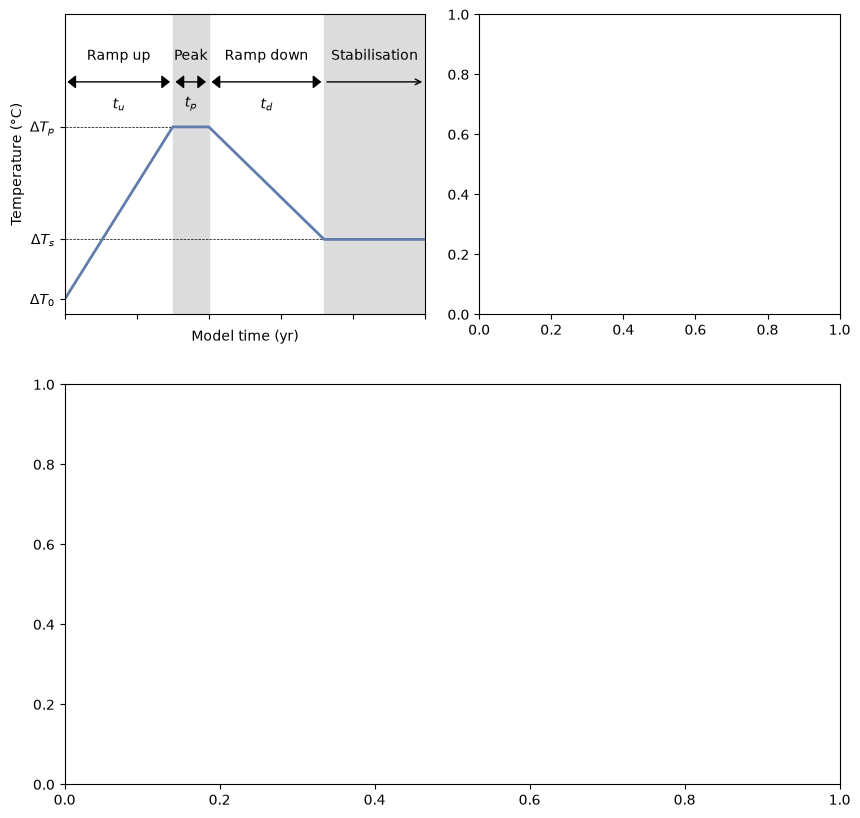

In [19]:
fig = plt.figure(figsize=(10,10))
gs = GridSpec(2, 2, figure=fig,height_ratios=[1.5,2])
ax1= fig.add_subplot(gs[0,0])
ax2= fig.add_subplot(gs[0,1])
ax3= fig.add_subplot(gs[1,0:])
axs=[ax1,ax2,ax3]
fig.subplots_adjust(wspace=0.15)

##### --------- STYLISED OS SUBPANEL ----------------------------------------------
axs[0].set_xlim(0,250)
axs[0].set_ylim(1,5)
ylim=axs[0].get_ylim()
xlim=axs[0].get_xlim()

stylized_par = (1.2,3.5,2,75,25,80)
dashed_ends = [0,stylized_par[3],np.sum(stylized_par[3:])]#[0,popt_of_m[3],np.sum(popt_of_m[3:])]
temp_names = [r'$\Delta T_0$', r'$\Delta T_p$', r'$\Delta T_s$']
dur_names = [r'$t_u$', r'$t_p$', r'$t_d$']
phase_names = ['Ramp up', 'Peak', 'Ramp down', 'Stabilisation']
y_phase,y_arrow,y_dur = (4.35,4.1,3.7)
xdata = np.arange(301)
for i in range(3):
    axs[0].plot([-20,dashed_ends[i]],[stylized_par[i]]*2,c='k',ls='--',lw=0.5)
    axs[0].annotate('',
                (np.sum(stylized_par[3:3+i]),y_arrow), 
                (np.sum(stylized_par[3:4+i]),y_arrow),
                arrowprops=dict(facecolor='black',arrowstyle='<|-|>,head_width=0.4,head_length=0.5')
               )
    axs[0].text(np.sum(stylized_par[3:3+i])+stylized_par[3+i]/2, y_dur,
            dur_names[i],va='bottom',ha='center')
    axs[0].text(np.sum(stylized_par[3:3+i])+stylized_par[3+i]/2, y_phase,
            phase_names[i],va='bottom',ha='center')
axs[0].text(np.mean([xlim[1],np.sum(stylized_par[3:])]), y_phase,
            phase_names[-1],va='bottom',ha='center')
axs[0].annotate('',
            (np.sum(stylized_par[3:]),y_arrow), 
            (xlim[1],y_arrow),
            arrowprops=dict(facecolor='black',arrowstyle='<-')
           )
axs[0].plot(xdata,OS_model(xdata,*stylized_par),color='#607dab',lw=2)#*np.median(popts,axis=0)))
axs[0].fill_betweenx(ylim,stylized_par[3],np.sum(stylized_par[3:5]),color='gainsboro',zorder=0)
axs[0].fill_betweenx(ylim,np.sum(stylized_par[3:]),xlim[1],color='gainsboro',zorder=0)

axs[0].set_xlabel("Model time (yr)")
axs[0].set_ylabel('Temperature (°C)')
axs[0].set_yticks(stylized_par[:3],temp_names)
axs[0].axes.xaxis.set_ticklabels([])


##### --------- CRITICAL THRESHOLDS SUBPANEL ---------------------------------
axs[1].bar(np.arange(9),[z-x for x,y,z in tps],bottom=[x for x,y,z in tps])
for i,v in enumerate(tps):
    x,y,z=v
    axs[1].imshow(np.linspace(x,z).reshape((50,1)), extent=[i-0.4,i+0.4,x,z], aspect="auto", 
              zorder=1,vmin=-5,vmax=9,cmap=node_cmap,origin='lower');
    axs[1].plot([i-0.4,i+0.4],[y]*2,c='k')
axs[1].set_xlim(-1,9)
axs[1].set_ylim(0,8.5)
axs[1].set_xticks(np.arange(9),df_TEs_sorted.index.values)
axs[1].tick_params("x", rotation=45)
axs[1].set_ylabel('Temperature (°C)')
# axs[1].yaxis.tick_right()
# axs[1].yaxis.set_label_position("right")


##### --------- NETWORK SUBPANEL -----------------------------------------------
m.fillcontinents(color='tan',lake_color='tan',ax=ax3,zorder=1);
m.drawcoastlines(color='k',zorder=0)

node_cmap = 'rocket'
vmin = -1
vmax = 8 
node_size=[1600/np.log(df_TEs.loc[n]['Collapse (years)']) for n in G.nodes]
im = nx.draw_networkx(G,ax=ax3,pos=pos_xy,
                 node_size=node_size,
                 with_labels=False,edgelist=[],
                 node_color=[T_lim_dic[n] for n in G.nodes()],
                 edgecolors='k',
                 vmin=vmin,vmax=vmax,cmap=node_cmap,
                 font_size=12,font_color='navy',font_weight=None)
for e in G.edges:
    vals = G.get_edge_data(e[0],e[1])
    if vals['min'] > 0: # Destabilising
        c = 'indianred'
        w = vals['max']
    elif vals['max'] < 0: # Stabilising
        c = 'royalblue'
        w= np.abs(vals['min'])
    else: # Unclear
        c = 'gray' 
        w = vals['max']
    nx.draw_networkx_edges(G,pos_xy,ax=ax3,edgelist=[e], 
                           edge_color=c, width=np.log(w)*1.4+0.4,
                           node_size=[n+100 for n in node_size],
                           connectionstyle="arc3,rad=rrr".replace('rrr',str(earc_dic[e])),
                           arrowsize=15
                          );

#### ------------ Lettering ------------------
for i,l in enumerate(['a','b','c']):
    axs[i].text(0.025,0.975, l ,va='top',ha='left',
                bbox=dict(boxstyle='round', fc="w",pad=0.1,ec='w'),weight='bold',fontsize=14,
                transform=axs[i].transAxes)

# fig.savefig('../../../Figures/Overshoots/NCC/illustrative_fig.pdf',bbox_inches='tight',dpi=300,format='pdf')

# 5 panels

In [2]:
folder = '../../../Data/PROVIDE 2025/fair_temperatures/'
scenarios = os.listdir(folder)
scen_to_plot = ['ssp119','ssp534-over','CurPol nz 2120 decline -23800']

temps = {s:pd.read_csv(folder+'scen_%s.csv'%s).set_index('year').to_numpy() for s in scen_to_plot}
years = np.arange(1850,2301)

t_ref=2015
xdata=years[t_ref-1850:]-t_ref

popts_of_m = {s:OS_fit(years[t_ref-1850:]-t_ref,
                       np.median(temps[s][t_ref-1850:,:],axis=1))[0] 
              for s in scen_to_plot}
popts = {s:np.array([curve_fit(OS_model, xdata, temps[s][t_ref-1850:,i],
                               p0=popts_of_m[s],
                               bounds = ([0, 0, 0, 0, 0, 0],
                                         [5, 5, 5, 200, 200, 200]) )[0] 
                   for i in range(temps[s].shape[1])]) 
         for s in scen_to_plot}

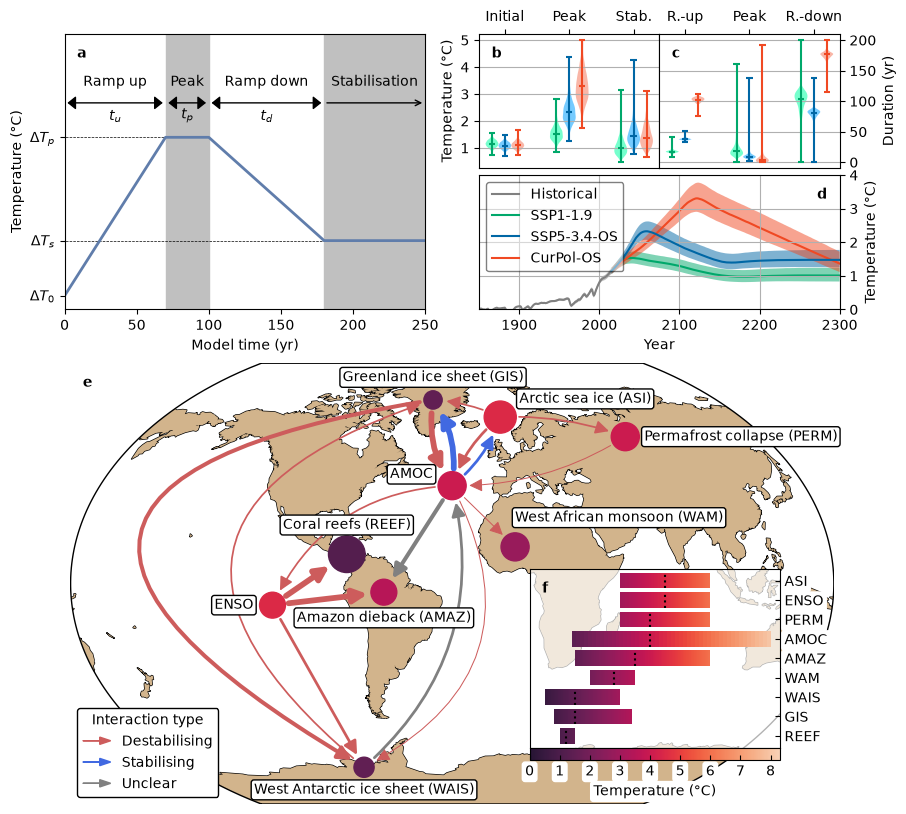

In [20]:
fig = plt.figure(figsize=(10,10))
gs = GridSpec(2, 2, figure=fig,height_ratios=[1.25,2],hspace=0.15,wspace=0.15)
ax1= fig.add_subplot(gs[0,0])

gs2 = mpl.gridspec.GridSpecFromSubplotSpec(2,2,subplot_spec=gs[0,1],hspace=0.05,wspace=0.0)
ax2_1 = fig.add_subplot(gs2[1,:])
ax2_2 = fig.add_subplot(gs2[0,0])
ax2_3 = fig.add_subplot(gs2[0,1])
axs=[ax2_2,ax2_3]

ax3= fig.add_subplot(gs[1,0:])
ax3_1= fig.add_axes((0.59,0.135,.25,0.21))
# fig.subplots_adjust(wspace=0.15,hspace=0.15)

ax1.set_xlim(0,250)
ax1.set_ylim(1,5)
illustrative_fig.stylisedOS_panel(fig,ax1,
                                  stylized_par=(1.2,3.5,2,70,30,80),phase_y=4.2)
illustrative_fig.network_panel(fig,ax3)
illustrative_fig.threshold_inset(fig,ax3_1)

### ----------
ax2_1.set_xlim(1850,2300)
ax2_1.set_ylim(0,4)
illustrative_fig.scenarios_panel(fig,ax2_1,legend_title='',legend_alpha=0.5)
ax2_1.set_ylabel('Temperature (°C)')
ax2_1.set_xlabel("Year")
ax2_1.yaxis.tick_right()
ax2_1.yaxis.set_label_position('right')
ax2_1.grid()

illustrative_fig.parDist_panel(fig,axs,popts)
for i in range(2):
    axs[i].xaxis.tick_top()
    axs[i].set_xlim(-0.4,2.4)
    axs[i].grid(axis='y')
axs[0].set_yticks([1,2,3,4,5])
axs[1].set_yticks([0,50,100,150,200])

locs=['upper left']*6
locs[3]='upper right'
for a,l,loc in zip([ax1,ax2_2,ax2_3,ax2_1,ax3,ax3_1],
                'abcdef',locs):
    preexisting_leg = a.get_legend()
    if preexisting_leg is not None:
        a.add_artist(preexisting_leg)
    a.legend(handles=[],title=l,
             loc=loc,
             title_fontproperties={'weight':'bold'},frameon=False)

fig.savefig('../../../Figures/Overshoots/NCC/illustrative_fig.pdf',bbox_inches='tight',dpi=300,format='pdf')

# Developping the double-panel with the real scenarios and their fitted parameters

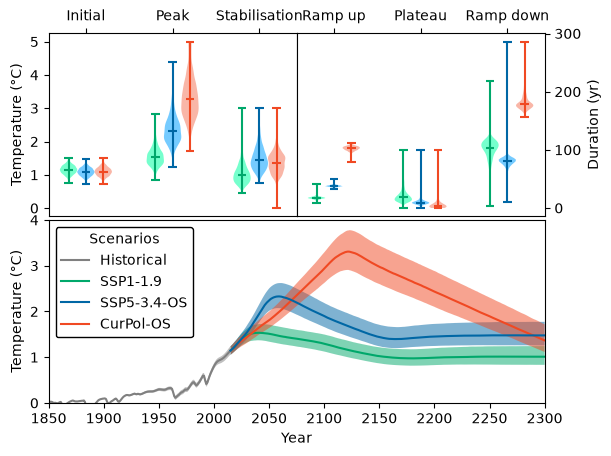

In [6]:
fig = plt.figure()
gs = GridSpec(2, 2, figure=fig)
ax1 = fig.add_subplot(gs[1,:])
ax2 = fig.add_subplot(gs[0,0])
ax3 = fig.add_subplot(gs[0,1])
axs=[ax2,ax3]
fig.subplots_adjust(hspace=0.02,wspace=0.0)

ax1.set_xlim(1850,2300)
ax1.set_ylim(0,4)
illustrative_fig.scenarios_panel(fig,ax1)
ax1.set_ylabel('Temperature (°C)')
# ax1.xaxis.tick_top()
# ax1.xaxis.set_label_position("top")
ax1.set_xlabel("Year")

colors = ['#00A86B', '#0067A5', '#F04923']
scen_to_plot = ['ssp119','ssp534-over','CurPol nz 2120 decline -23800']
for i,s in enumerate(scen_to_plot):
    axs[0].violinplot([popts[s][:,i] for i in range(3)],widths=0.2,
                      positions=np.arange(3)+(i-1)*0.2,facecolor=lighten_color(colors[i],0.4),linecolor=colors[i],showmedians=True)
    axs[1].violinplot([popts[s][:,3+i] for i in range(3)],widths=0.2,
                      positions=np.arange(3)+(i-1)*0.2,facecolor=lighten_color(colors[i],0.4),linecolor=colors[i],showmedians=True)

axs[0].set_ylabel('Temperature (°C)')
axs[0].set_xticks([0,1,2],['Initial', 'Peak', 'Stabilisation'])

axs[1].set_ylabel('Duration (yr)')
axs[1].set_xticks([0,1,2],['Ramp up', 'Plateau', 'Ramp down'])
axs[1].yaxis.tick_right()
axs[1].yaxis.set_label_position("right")

for i in range(2):
    axs[i].xaxis.tick_top()

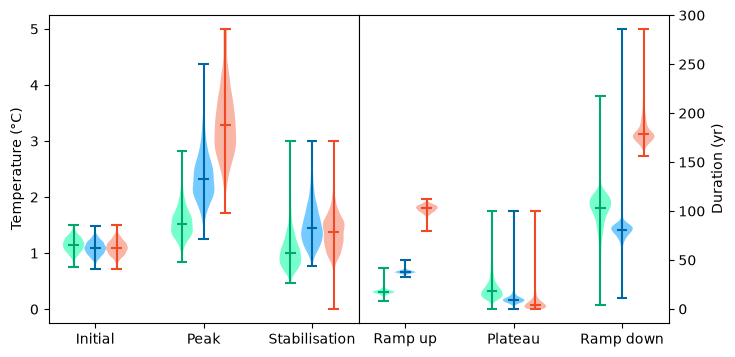

In [17]:
fig,axs=plt.subplots(ncols=2,figsize=(8,4))
fig.subplots_adjust(wspace=0)

colors = ['#00A86B', '#0067A5', '#F04923']

for i,s in enumerate(scen_to_plot):
    axs[0].violinplot([popts[s][:,i] for i in range(3)],widths=0.2,
                      positions=np.arange(3)+(i-1)*0.2,facecolor=lighten_color(colors[i],0.4),linecolor=colors[i],showmedians=True)
    axs[1].violinplot([popts[s][:,3+i] for i in range(3)],widths=0.2,
                      positions=np.arange(3)+(i-1)*0.2,facecolor=lighten_color(colors[i],0.4),linecolor=colors[i],showmedians=True)

axs[0].set_ylabel('Temperature (°C)')
axs[0].set_xticks([0,1,2],['Initial', 'Peak', 'Stabilisation'])

axs[1].set_ylabel('Duration (yr)')
axs[1].set_xticks([0,1,2],['Ramp up', 'Plateau', 'Ramp down'])
axs[1].yaxis.tick_right()
axs[1].yaxis.set_label_position("right")

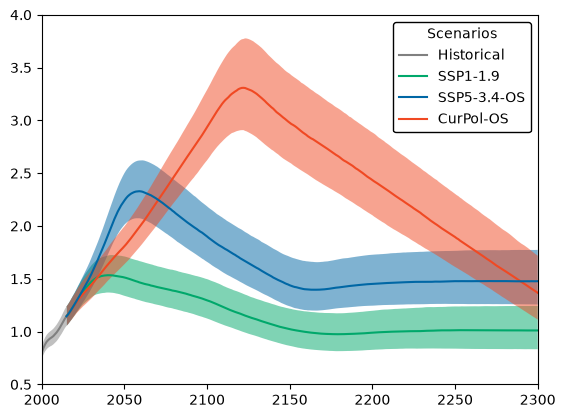

In [18]:
fig,ax=plt.subplots()
colors = ['#00A86B', '#0067A5', '#F04923']
labels = ['SSP1-1.9','SSP5-3.4-OS','CurPol-OS']
zorders=[1,2,1]
t_ref=2015
ax.set_xlim(2000,2300)
ax.set_ylim(0.5,4)
ax.fill_between(years[:t_ref+1-1850],
                np.quantile(temps['ssp119'],0.25,axis=1)[:t_ref+1-1850],
                np.quantile(temps['ssp119'],0.75,axis=1)[:t_ref+1-1850],
                color=lighten_color('gray',0.5),edgecolor='none')
ax.plot(years[:t_ref+1-1850],np.median(temps['ssp119'],axis=1)[:t_ref+1-1850],color='gray',label='Historical')
for i,s in enumerate(scen_to_plot):
    ax.fill_between(years[t_ref-1850:],
                    np.quantile(temps[s],0.25,axis=1)[t_ref-1850:],
                    np.quantile(temps[s],0.75,axis=1)[t_ref-1850:],
                    color=lighten_color(colors[i],1),alpha=0.5,edgecolor='none',zorder=0)
    ax.plot(years[t_ref-1850:],
            np.median(temps[s],axis=1)[t_ref-1850:],
            color=colors[i],
            label=labels[i],
            zorder=zorders[i])

ax.legend(edgecolor='k',framealpha=1,title='Scenarios')

## Debating whether to show the ensemble for curpol_os_1.5C
None of the ensemble of CurPol nz 2120 decline -23800 actually stabilises. It seems that the "OS_1.5C" was externally enforced by the PROVIDE project such that the tier 1 summary temperatures wereset to be 1.5C once the median came back to 1.5C until 2300. As such the median of the actual ensemble is not the same as the summary temperature (at least for the last decade or two).

In [ ]:
folder = '../../../Data/PROVIDE 2025/fair_temperatures/'
scenarios = os.listdir(folder)
baseline = 'ssp534-over'
df_s_ensemble = pd.read_csv(folder+'scen_%s.csv'%baseline)
df_s_ensemble = df_s_ensemble.set_index('year')
years = df_s_ensemble.index.values
temps=df_s_ensemble.to_numpy()

t_ref = 2015
xdata=years[t_ref-1850:]-t_ref
popts = np.array([OS_fit(xdata,temps[t_ref-1850:,r])[0] for r in range(temps.shape[1])])
popt_m_en,_ = OS_fit(xdata,np.median(temps[t_ref-1850:,:],axis=1)) # median of ensemble

popt_m_sum,_= OS_fit(xdata,df[baseline].to_numpy()[t_ref-1850:]) # summary statistic

In [ ]:
s_en = 'ModAct nz 2120 decline -23000'#CurPol nz 2120 decline -23800'
s_sum = 'ModAct_OS_1C'#'CurPol_OS_1.5C'
temps_en = pd.read_csv(folder+'scen_%s.csv'%s_en).set_index('year').to_numpy()
plt.plot(xdata+t_ref,df[s_sum].to_numpy()[t_ref-1850:],label=s_sum) 
plt.plot(xdata+t_ref,np.median(temps_en[t_ref-1850:,:],axis=1),label=s_en)
# plt.plot(xdata+t_ref,
#          df[s_sum].to_numpy()[t_ref-1850:]-
#          np.median(temps_en[t_ref-1850:,:],axis=1))

plt.legend()

In [ ]:
scenarios

In [ ]:
plt.boxplot(temps_en[-1,:])

In [ ]:
for i in range(22):
    plt.plot(years,temps_en[:,i*100],c='k',lw=0.5)
plt.plot([1850,2300],[1.5]*2)